# Visual validation notebook for the ``extended_disk`` experiment
Do NOT run and update this notebook itself (except when actually amending or improving it).   Instead, use the "Duplicate" option to make a copy, and use that to do visual validation.

In [1]:
%load_ext autoreload
%autoreload 2
%pylab inline

Populating the interactive namespace from numpy and matplotlib


## How to use ``imshow().set_transform()``

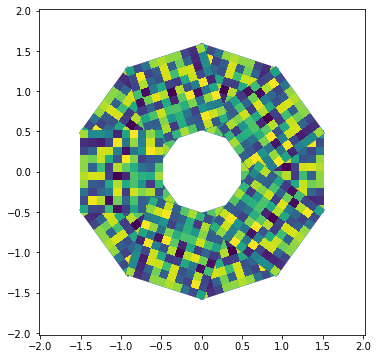

In [2]:
import matplotlib.transforms as mt
def cylinder(A,n=100,r=1):
    dphi=2*pi/n
    s=r*dphi*(1+dphi)
    for i in range(0,n,2):
        imshow(A,extent=[1-s/2,1+s/2,-s/2,s/2],interpolation='nearest',clip_on=1
        ).set_transform(mt.Affine2D().rotate_around(0,0,i*dphi)+gca().transData)
    for i in range(1,n,2):
        imshow(A,extent=[1-s/2,1+s/2,-s/2,s/2],interpolation='nearest',clip_on=1
        ).set_transform(mt.Affine2D().rotate_around(0,0,i*dphi)+gca().transData)
    S=1+s; xlim(-S,S); ylim(-S,S)
n=10; A=random.random((n,n))
W=6; figure(figsize=(W,W))
cylinder(A,10)

## Visualizing actual data

### Standard startup

In [3]:
top='c:/cygwin64/home/codes/dispatch2/'
import os
os.chdir(top+'experiments/extended_disk/python')
import sys
sys.path.insert(0,top+'utilities/python')
import dispatch as dis
import dispatch.select as dse
import dispatch.graphics as dgr
import dispatch.particles as dpa

### Read a snapshot

In [4]:
run=''
run='devel'
sn=dis.snapshot(0,run,verbose=0)
pp=sn.patches
sn.io.nml_version,sn.io.method,sn.patches[0].nv

(5, 'background      ', 5)

### A single patch
### at t=0

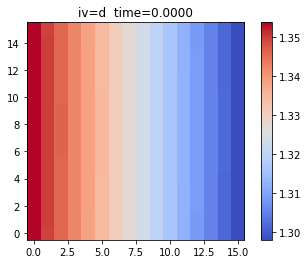

In [5]:
def ShowPatch(io=0,iv='d',run='devel',ip=0,all=0):
    sn=dis.snapshot(io,run,verbose=0)
    p=sn.patches[ip]; n=p.n[2]
    dgr.imshow(p.var(iv,all=all)[:,:,n//2])
    title('iv={}  time={:.4f}'.format(iv,sn.time));
ShowPatch()

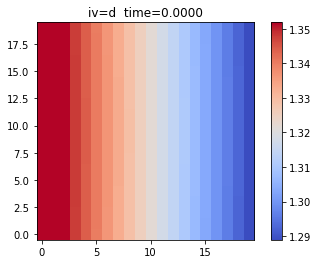

In [6]:
ShowPatch(all=1)

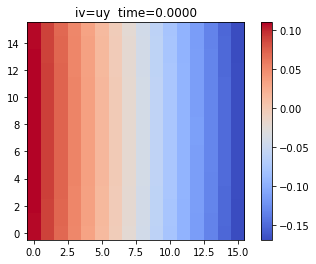

In [7]:
ShowPatch(0,'uy')

#### after one timestep

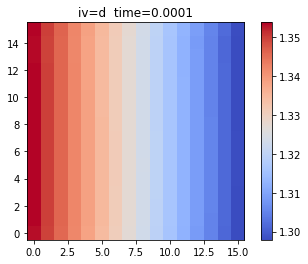

In [8]:
ShowPatch(1,'d',ip=100)

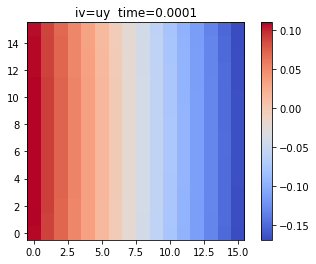

In [9]:
ShowPatch(1,'uy',ip=100)

### Radial dependence

In [10]:
def PlotRadial(io=4,iv='d',run='devel',ip=0):
    D={}
    for io in range(0,io+1,io):
        sn=dis.snapshot(io,run)
        for i in range(5):
            p=pp[ip+318*i]
            k=(io,i)
            D[k]=p
            k=(0,i)
            p=D[k]
            r=p.centre_nat[0]
            f=p.var(iv)
            if iv=='uy':
                v_phi=p.omega[2]*r
                f=p.var('uy')+v_phi
            m=p.n[0]
            n=m//2
            if m%2==0:
                f=(f[:,n,n]+f[:,n-1,n-1])/2
            else:
                f=f[:,n,n]
            if io==0:
                plot(p.xi,f,'b')
            else:
                plot(p.xi,f,'g') 
    xlabel('R'); ylabel(iv); title('time={:.4f}'.format(sn.time));

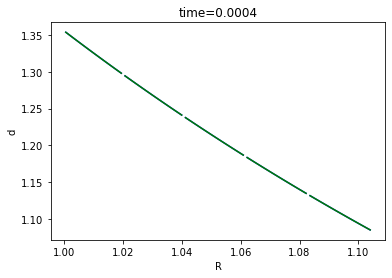

In [11]:
PlotRadial()

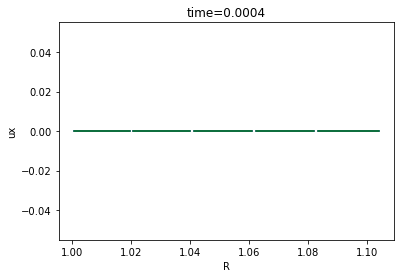

In [12]:
PlotRadial(4,'ux')

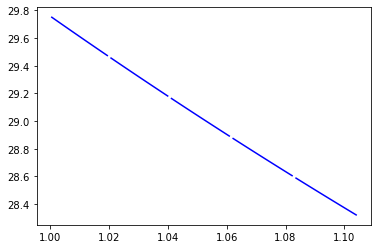

In [13]:
ip=0
c='b'
D={}
for io in range(0,1,3):
    sn=dis.snapshot(io,run)
    for i in range(5):
        p=pp[ip+318*i]
        k=(io,i)
        D[k]=p
        k=(0,i)
        p=D[k]
        r=p.centre_nat[0]
        v_phi=p.omega[2]*r
        uy=p.var('uy')+v_phi
        if io==0:
            plot(p.xi,uy[:,8,8],'b')
        else:
            plot(p.xi,uy[:,8,8],'g') 
#xlim(0.996,1.02)
#ylim(29.4,29.8);

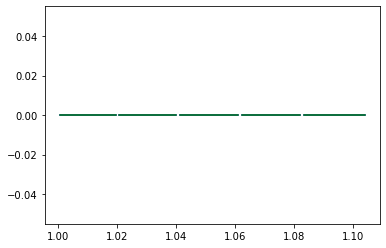

In [14]:
ip=0
iv='ux'
p={}
for io in range(0,3,2):
    sn=dis.snapshot(io,run)
    for i in range(5):
        k=(io,i)
        p[k]=pp[io+318*i]
        k=(0,i)
        m=p[k].n[0]
        n=m//2
        u=p[k].var(iv)
        if m%2==0:
            u=(u[:,n,n]+u[:,n-1,n-1])/2
        else:
            u=u[:,n,n]
        if io==0:
            plot(p[k].xi,u,'b')
        else:
            plot(p[k].xi,u,'g') 

### Show a disk section

In [15]:
import matplotlib.transforms as mt
def ShowDisk(io=0,iv='d',run='devel',select='top'):
    sn=dis.snapshot(io,run,verbose=0)
    nphi=318
    dphi=2*pi/nphi

    W=15; figure(figsize=(W,W))
    i0=nphi//4
    if select=='top':
        pp=[p for p in sn.patches if abs(p.position[0]) < 0.1 and p.position[1]>0]
    elif select=='right':
        pp=[p for p in sn.patches if abs(p.position[1]) < 0.1 and p.position[0]>0]
    else:
        pp=sn.patches
    vmax=0
    vmin=1e9
    for p in pp:
        n=p.n[0]
        v=p.var(iv)[:,:,n//2]
        r=p.centre_nat[0]
        v_phi=p.omega[2]*r
        if iv=='uy':
            v=v+v_phi
        vmin=min(vmin,v.min())
        vmax=max(vmax,v.max())
    for p in pp:
        r=p.centre_nat[0]
        phi=p.centre_nat[1]
        s=r*dphi*(1+dphi)
        v=p.var(iv)[:,:,n//2].transpose()
        r=p.centre_nat[0]
        v_phi=p.omega[2]*r
        if iv=='uy':
            v=v+v_phi
        imshow(v,extent=[r-s/2,r+s/2,-s/2,s/2],interpolation='nearest',clip_on=1,vmin=vmin,vmax=vmax
        ).set_transform(mt.Affine2D().rotate_around(0,0,phi)+gca().transData)
    if select=='top':
        S=r+s; ylim(1-s/2,r+s*0.7); xlim(-5.5*s,5*s);
    elif select=='right':
        S=r+s; xlim(1-s/2,r+s*0.7); ylim(-5.5*s,5*s);
    else:
        S=r+s; w=1+6*s; xlim(-w,w); ylim(-w,w);
    title('iv={}  time={:.4f}'.format(iv,sn.time));

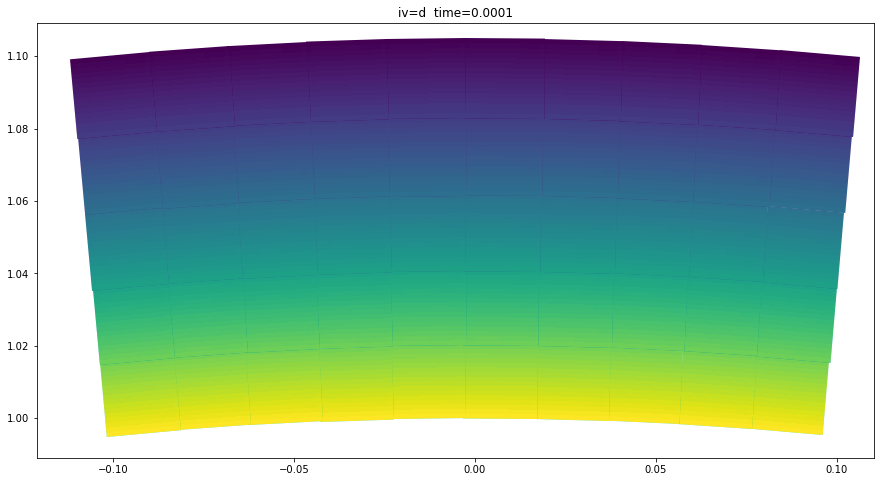

In [16]:
ShowDisk(1,'d','devel','top')

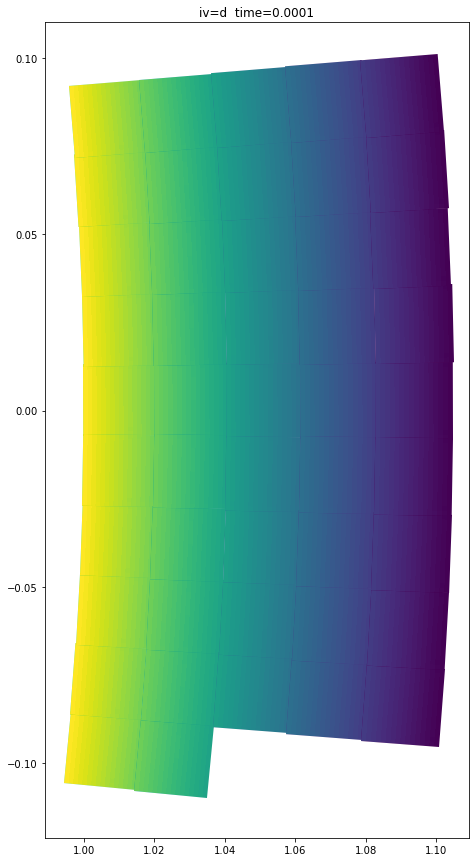

In [17]:
ShowDisk(1,'d','devel','right')

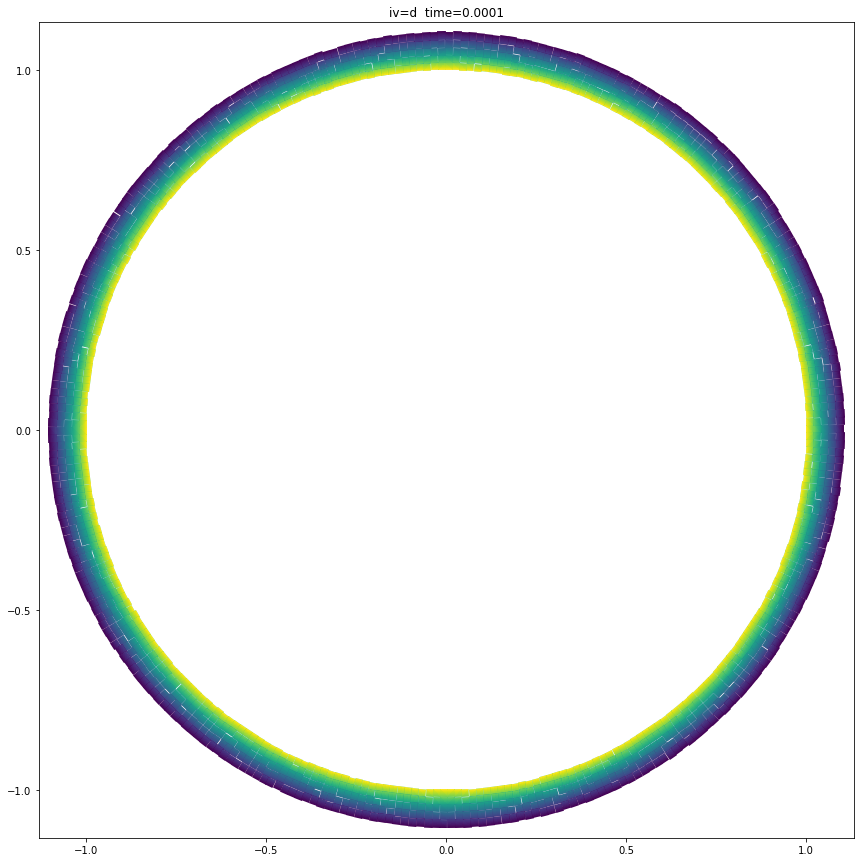

In [18]:
ShowDisk(1,'d','devel','all')

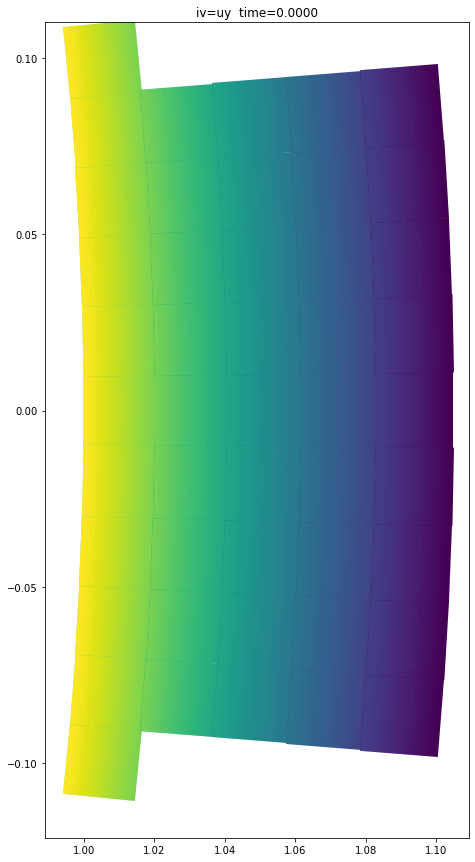

In [19]:
ShowDisk(0,'uy','devel','right')

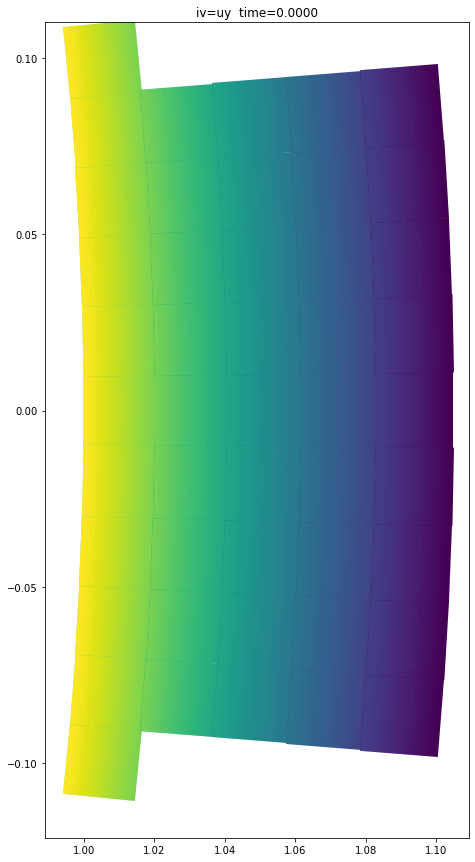

In [20]:
ShowDisk(0,'uy','devel','right')

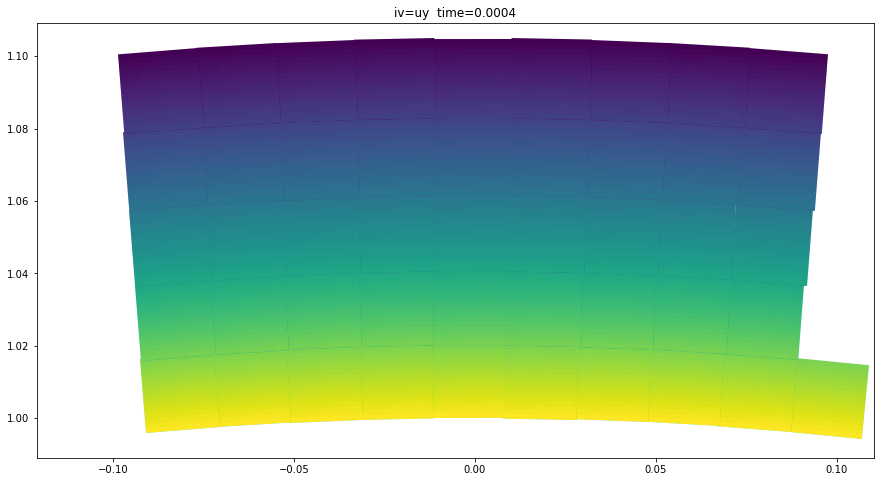

In [21]:
ShowDisk(4,'uy','devel','top')

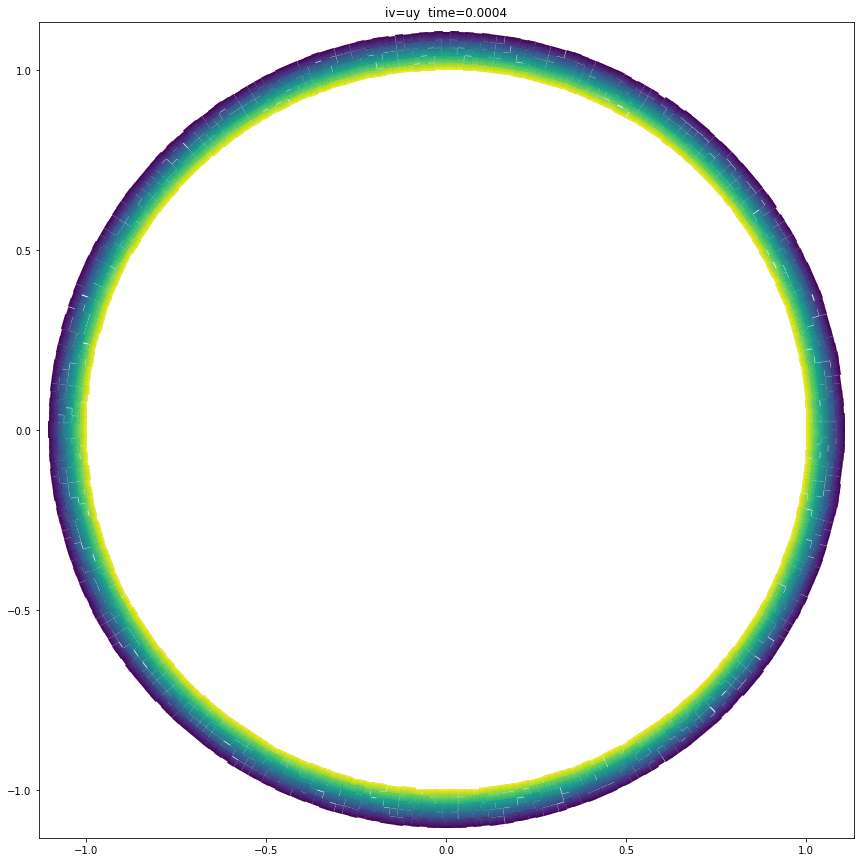

In [22]:
ShowDisk(4,'uy','devel','all')

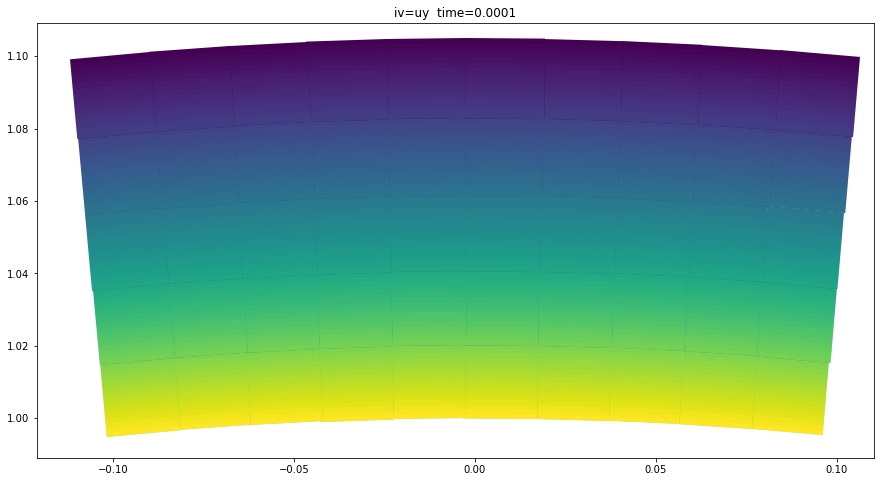

In [23]:
ShowDisk(1,'uy')

### Check density range

In [24]:
all=False
for io in range(4):
    sn=dis.snapshot(io,'devel')
    pp=sn.patches
    p=pp[0]
    d=p.var('d')
    dmin=d.min()
    dmax=d.max()
    for p in pp[1:]:
        d=p.var('d',all=all)
        dmin=min(dmin,d.min())
    print('{}  {:.4f}  {:.4f}'.format(io,dmin,dmax))

0  1.0465  1.3538
1  1.0463  1.3538
2  1.0462  1.3541
3  1.0460  1.3544


## Time- and length-scales

In [25]:
sn=dis.snapshot(0,'devel')
pp=sn.patches
p=pp[0]
v_phi=p.velocity[1]
r=p.centre_nat[0]
n_phi=318
s=r*2*pi/n_phi
t_patch=s/v_phi
t_cell=t_patch/p.n[0]
print('v_phi={:.2f} km/s  t_patch={:.2e}   t_cell={:.2e}'.format(v_phi,t_patch,t_cell))

v_phi=29.61 km/s  t_patch=6.74e-04   t_cell=4.21e-05


In [26]:
p=pp[0]
n=p.n[0]
i=n//2
gamma=sn.eos.gamma
g1=1 if gamma==1 else gamma-1
P_g=g1*p.var('eth')[i,i,i]
rho=p.var('d')[i,i,i]
c_s=(gamma*P_g/rho)
Courant=0.25
t_step=Courant*s/c_s/p.n[0]
cell=s/n
n_patch=t_step*v_phi/s
n_cell=t_step*v_phi/cell
print('gamma: {:.2f}   sound speed: {:.2f} km/s   timestep: {:.2e}   patches/step: {:.2f}'.format(
    gamma,c_s,t_step,n_patch))

gamma: 1.00   sound speed: 0.99 km/s   timestep: 3.16e-04   patches/step: 0.47


There are 318 patches around the circle, and it would take about 600 steps for one orbit according to the above.  This is consistent with a speed of 30 in code units, a circumference of of about 6, so an orbit time of about 0.2 time units, and a timestep of about 3.5e-4:

In [27]:
int(0.2/3.5e-4)

571

## Notes